# Lab 00-01 · Calculators for the Map of EE

Companion to chapter [00-01](../../chapters/00-01-map-of-electrical-engineering.md). Handout: [README.md](README.md).

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## 1 — Battery energy

In [2]:
def battery(mAh, volts, hours=None):
    wh = mAh / 1000 * volts
    print(f"{mAh} mAh at {volts} V = {wh:.3g} Wh = {wh * 3600 / 1000:.3g} kJ", end="")
    if hours:
        print(f"; average power over {hours} h = {wh / hours * 1000:.3g} mW")
    else:
        print()
    return wh

battery(4000, 3.85, 24)    # Example 00-01.1
battery(300, 3.85, 48)     # Problem 00-01.2
assert abs(battery(4000, 3.85) - 15.4) < 1e-12

4000 mAh at 3.85 V = 15.4 Wh = 55.4 kJ; average power over 24 h = 642 mW
300 mAh at 3.85 V = 1.16 Wh = 4.16 kJ; average power over 48 h = 24.1 mW
4000 mAh at 3.85 V = 15.4 Wh = 55.4 kJ


## 2 — Energy per bit

In [3]:
def link_power(gbps, pj_per_bit, lanes=1):
    p = gbps * 1e9 * pj_per_bit * 1e-12 * lanes
    print(f"{lanes} × {gbps} Gb/s at {pj_per_bit} pJ/bit = {p:.3g} W")
    return p

link_power(112, 5); link_power(112, 5, 64); link_power(400, 15, 64)

1 × 112 Gb/s at 5 pJ/bit = 0.56 W
64 × 112 Gb/s at 5 pJ/bit = 35.8 W
64 × 400 Gb/s at 15 pJ/bit = 384 W


384.0

## 3 — Shannon capacity

**🔮 Predict:** at 20 dB SNR, is an 80 MHz channel better than a 20 MHz channel at 40 dB?

80 MHz @ 20 dB: 532.7 Mb/s
20 MHz @ 40 dB: 265.8 Mb/s


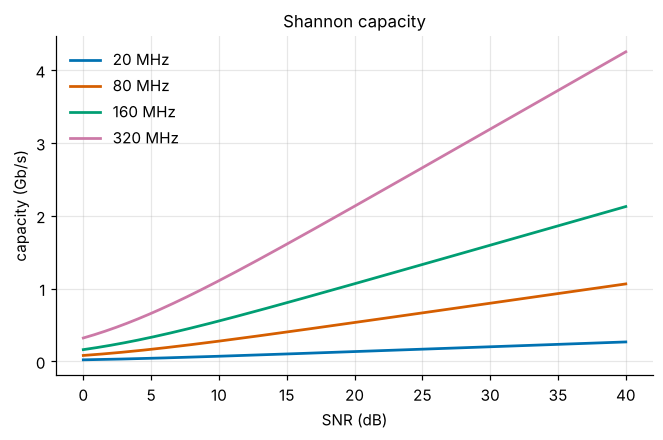

In [4]:
def capacity(bw_hz, snr_db):
    return bw_hz * math.log2(1 + 10 ** (snr_db / 10))

print(f"80 MHz @ 20 dB: {capacity(80e6, 20) / 1e6:.1f} Mb/s")
print(f"20 MHz @ 40 dB: {capacity(20e6, 40) / 1e6:.1f} Mb/s")
snr = np.linspace(0, 40, 200)
plt.figure(figsize=(7, 4))
for bw in [20e6, 80e6, 160e6, 320e6]:
    plt.plot(snr, [capacity(bw, s) / 1e9 for s in snr], label=f"{bw / 1e6:.0f} MHz")
plt.xlabel("SNR (dB)"); plt.ylabel("capacity (Gb/s)"); plt.legend(); plt.title("Shannon capacity")
plt.show()
assert capacity(80e6, 20) > capacity(20e6, 40)

## 4 — The market by segment (dated data)

**Data as of Nov 2026:** WSTS 2025 actuals, research-log entry R-016. To update: replace the numbers below with the latest WSTS release, update the date, and add a new dated line to the research log.

Logic            $  299.5 B   37.6%
Memory           $  230.0 B   28.9%
Analog           $   86.5 B   10.9%
Micro            $   84.9 B   10.7%
Optoelectronics  $   43.0 B    5.4%
Discretes        $   30.7 B    3.9%
Sensors          $   20.9 B    2.6%
Total            $  795.6 B   (WSTS 2025 actuals (R-016, checked Nov 2026))


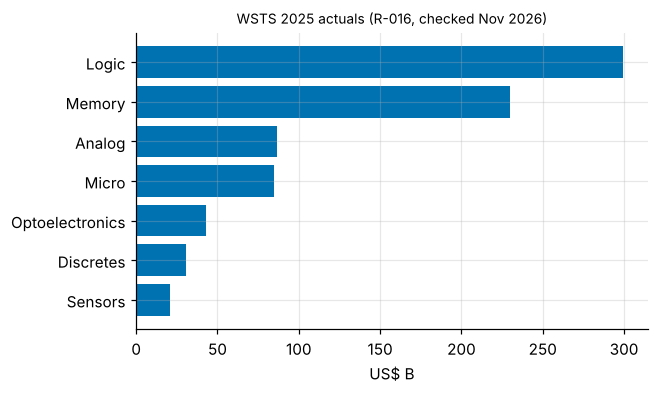

In [5]:
AS_OF = "WSTS 2025 actuals (R-016, checked Nov 2026)"
segments = {"Logic": 299.547, "Memory": 230.042, "Analog": 86.519, "Micro": 84.867,
            "Optoelectronics": 43.042, "Discretes": 30.728, "Sensors": 20.894}  # US$ B
total = sum(segments.values())
for k, v in segments.items():
    print(f"{k:<16} ${v:7.1f} B  {100 * v / total:5.1f}%")
print(f"{'Total':<16} ${total:7.1f} B   ({AS_OF})")
plt.figure(figsize=(6, 3.5)); plt.barh(list(segments)[::-1], list(segments.values())[::-1])
plt.xlabel("US$ B"); plt.title(AS_OF, fontsize=9); plt.show()